In [2]:
from pathlib import Path
import math

import pandas as pd
import tensorflow as tf
from tensorflow import keras

# Project paths
BASE_DIR = Path.cwd().parent
DATA_PATH = BASE_DIR / "data" / "rossmann" / "train.csv"
MODEL_PATH = BASE_DIR / "models" / "demand_lstm.keras"

MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

In [3]:
df = pd.read_csv(DATA_PATH, parse_dates=["Date"])

# Select one store for a simple first version
df = df[df["Store"] == 1].copy()

# Sort by date
df = df.sort_values("Date")

# Keep only date and sales
df = df[["Date", "Sales"]]

# Set date as index
df = df.set_index("Date")

# Ensure daily frequency
df = df.asfreq("D")

# Missing sales are kept as missing, not assumed zero
df = df.dropna()

print(df.head())
print("Total records:", len(df))

            Sales
Date             
2013-01-01      0
2013-01-02   5530
2013-01-03   4327
2013-01-04   4486
2013-01-05   4997
Total records: 942


C:\Users\rupam\AppData\Local\Temp\ipykernel_8844\2106922432.py:1: DtypeWarning: Columns (7: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH, parse_dates=["Date"])


In [4]:
sales = df["Sales"]

# 80% training, 20% testing
split = int(len(sales) * 0.8)

train_sales = sales.iloc[:split]

# Scale using training data only
max_sales = train_sales.max()

scaled_sales = sales / max_sales

print("Training days:", split)
print("Testing days:", len(sales) - split)

Training days: 753
Testing days: 189


In [5]:
LOOKBACK = 30

X_train, y_train = [], []
X_test, y_test = [], []

values = scaled_sales.tolist()
dates = scaled_sales.index

for i in range(LOOKBACK, len(values)):

    # Skip windows with missing calendar dates
    window_dates = dates[i - LOOKBACK:i + 1]

    if (window_dates[-1] - window_dates[0]).days != LOOKBACK:
        continue

    X = values[i - LOOKBACK:i]
    y = values[i]

    if i < split:
        X_train.append(X)
        y_train.append(y)
    else:
        X_test.append(X)
        y_test.append(y)

# Convert to tensors and reshape
X_train = tf.constant(X_train, dtype=tf.float32)
X_test = tf.constant(X_test, dtype=tf.float32)

y_train = tf.constant(y_train, dtype=tf.float32)
y_test = tf.constant(y_test, dtype=tf.float32)

X_train = tf.reshape(X_train, (-1, LOOKBACK, 1))
X_test = tf.reshape(X_test, (-1, LOOKBACK, 1))

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (723, 30, 1)
Testing shape: (189, 30, 1)


In [6]:
model = keras.Sequential([
    keras.Input(shape=(30, 1)),

    keras.layers.LSTM(32),

    keras.layers.Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    shuffle=False,
    verbose=1
)

Epoch 1/20


23/23 ━━━━━━━━━━━━━━━━━━━━ 15s 193ms/step - loss: 0.0777 - mae: 0.2199
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0488 - mae: 0.1697
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0482 - mae: 0.1598
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0479 - mae: 0.1609
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.0477 - mae: 0.1608
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0475 - mae: 0.1607
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0473 - mae: 0.1607
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0471 - mae: 0.1608
Epoch 9/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0470 - mae: 0.1608
Epoch 10/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0468 - mae: 0.1606
Epoch 11/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0466 - mae: 0.1604
Epoch 12/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0465 - mae: 0.1601
Epoch 13/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms

In [8]:
# Predict test sales
predictions = model.predict(X_test).flatten()

# Convert predictions back to original sales scale
predictions = predictions * max_sales
actual = y_test.numpy() * max_sales

# Calculate errors
mae = sum(abs(a - p) for a, p in zip(actual, predictions)) / len(actual)

rmse = math.sqrt(
    sum((a - p) ** 2 for a, p in zip(actual, predictions))
    / len(actual)
)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 339ms/step
MAE: 1343.41
RMSE: 1889.32


   Actual Sales  Predicted Sales
0   4839.999829      4093.475562
1      0.000000      3995.447521
2   4780.999909      4260.643041
3   4806.000010      4038.191214
4   4310.000081      3958.677991
5   5171.000002      3938.587782
6   5576.999910      3869.748769
7   5363.000048      3826.717429
8      0.000000      3839.605648
9   6037.999925      4220.059407


<Axes: title={'center': 'Actual vs Predicted Store Sales'}>

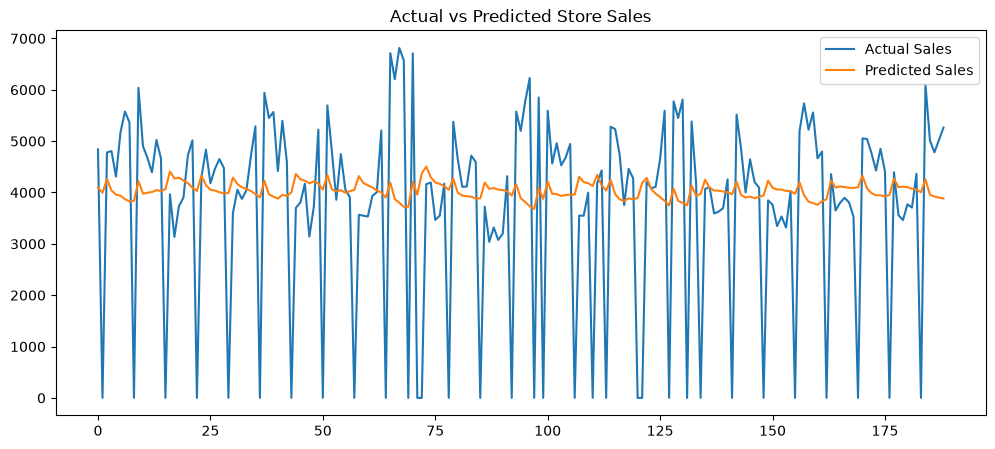

In [9]:
results = pd.DataFrame({
    "Actual Sales": actual,
    "Predicted Sales": predictions
})

print(results.head(10))

# Plot comparison
results.plot(
    title="Actual vs Predicted Store Sales",
    figsize=(12, 5)
)

In [10]:
model.save(MODEL_PATH)

print("Model saved successfully!")

Model saved successfully!


In [11]:
# Use the latest 30 consecutive days
last_30 = scaled_sales.iloc[-30:]

if (last_30.index[-1] - last_30.index[0]).days != 29:
    raise ValueError("The latest 30 days are not consecutive.")

# Reshape for LSTM
next_input = tf.constant(
    last_30.tolist(),
    dtype=tf.float32
)

next_input = tf.reshape(next_input, (1, 30, 1))

# Predict
next_day_sales = model.predict(next_input)[0][0]

# Reverse scaling
next_day_sales = max(0, next_day_sales * max_sales)

print("Predicted next-day sales:", round(float(next_day_sales), 2))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
Predicted next-day sales: 3872.76
